# 4. Does a goal change what happens next?

It's worth testing the memoryless property, since football might break this. A team that concedes may attack more, or a team that scores may sit back.

We will be working on the rescaled clock from notebook 3, where the fitted log-linear rate becomes constant and each match runs from 0 to 1. Under the Poisson model, a match with *n* goals has its goal times distributed like *n* independent uniform draws on (0, 1). A standard fact about uniform draws then gives:

- the time of the first goal follows a Beta(1, n) distribution, and
- so does the gap between the first and second goals.

If scoring makes another goal come sooner, the gaps will be shorter than Beta(1, n) predicts. If it slows the game, they will be longer.

In [4]:
import sys
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import scipy.stats as st
from scipy.optimize import minimize_scalar
import matplotlib.pyplot as plt
from load import load

matches, goals = load("../data/worldcup.json")

T = 90.0
reg = goals[~goals.in_extra_time]
clean = reg[reg.stoppage == 0].copy()
rng = np.random.default_rng(0)
clean["t"] = clean.minute.to_numpy() - rng.uniform(0, 1, len(clean))

t = clean.t.to_numpy()
loglik = lambda b: np.sum(np.log(b) + b * t - np.log(np.expm1(b * T)))
b_hat = minimize_scalar(lambda b: -loglik(b), bounds=(1e-6, 0.1), method="bounded").x
clean["u"] = np.expm1(b_hat * clean.t) / np.expm1(b_hat * T)
print(f"b = {b_hat:.5f}")

b = 0.00508


## 4.1 One number per match

For each match take the first-goal time, and (if there are at least two goals) the gap to the second goal. Matches are independent of each other, so using one value per match gives independent observations.

Matches have different numbers of goals, so their Beta(1, n) distributions differ. To pool them, pass each value through its own Beta(1, n) distribution function, `1 - (1 - x)^n`. If the model is right, the results are uniform on (0, 1) whatever n was. 

In [5]:
first_goal, gap = [], []
for match_id, grp in clean.groupby("match_id"):
    u = np.sort(grp.u.to_numpy())
    n = len(u)
    first_goal.append(1 - (1 - u[0]) ** n)
    if n >= 2:
        gap.append(1 - (1 - (u[1] - u[0])) ** n)

first_goal, gap = np.array(first_goal), np.array(gap)
print(f"matches with at least one goal:  {len(first_goal)}")
print(f"matches with at least two goals: {len(gap)}")

matches with at least one goal:  259
matches with at least two goals: 201


## 4.2 Test both against uniform

time of first goal           n = 259   mean = 0.496 (z-test p = 0.814)   KS p = 0.933
gap, first to second goal    n = 201   mean = 0.527 (z-test p = 0.181)   KS p = 0.114


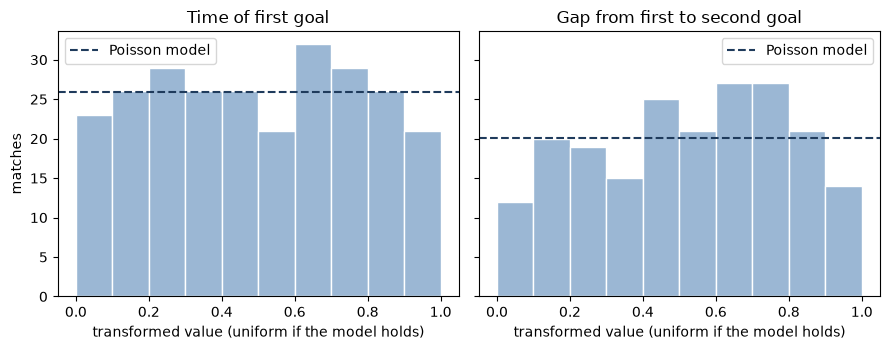

In [7]:
def report(name, x):
    ks = st.kstest(x, "uniform")
    z = (x.mean() - 0.5) / np.sqrt(1 / 12 / len(x))
    p_mean = 2 * st.norm.sf(abs(z))
    print(f"{name:<28} n = {len(x)}   mean = {x.mean():.3f} (z-test p = {p_mean:.3f})"
          f"   KS p = {ks.pvalue:.3f}")

report("time of first goal", first_goal)
report("gap, first to second goal", gap)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), sharey=True)
for ax, x, title in zip(axes, [first_goal, gap],
                        ["Time of first goal", "Gap from first to second goal"]):
    ax.hist(x, bins=10, range=(0, 1), color="#9bb7d4", edgecolor="white")
    ax.axhline(len(x) / 10, color="#1f3b5c", linestyle="--", label="Poisson model")
    ax.set_title(title)
    ax.set_xlabel("transformed value (uniform if the model holds)")
    ax.legend()
axes[0].set_ylabel("matches")
fig.tight_layout()
fig.savefig("../figures/04_memory.png", dpi=150)
plt.show()

## Conclusion

There is no evidence here that a goal changes what happens next. On the rescaled clock, the time of the first goal matches the Poisson prediction closely (259 matches, KS p = 0.93). The gap from the first goal to the second is also consistent with it (201 matches, KS p = 0.11). The gaps are slightly longer than predicted on average (mean 0.527 against 0.5), which would point to scoring slowing the game, but the difference is not significant (p = 0.18).

This is a failure to find memory, not proof that there is none. With 201 matches the test would only detect a fairly large effect, and it looks at one feature, the first gap. It also cannot separate which team scored: a fuller analysis of game state would model each team's rate as a function of the current score.